# 抓杯子：从新采集到新权重的完整实训

本篇执行红杯单任务的完整实验：40 个固定种子采集 → 全部入库轨迹的物理回放 → 5000 次 ACT［动作分块变换器］训练更新 → 30 个新种子闭环评估。采集为脚本专家控制；评估只使用学习策略输出。

本篇的新实验与旧红蓝杯历史成绩分别展示。打开文件直接查看已保存输出；重新执行完整实验时设置 `AMD_RUN_FULL=1`，并给出下面的工程、解释器和外置结果路径。未开启执行开关时显示本次已保存证据。


## 环境、输入与输出

复用已安装的 ROCm［AMD异构计算平台］训练环境与匹配的旧版 LeRobot 代码。仿真资产取自原抓杯子工程的 `asset` 文件夹。结果目录独立保存数据、日志、新权重和视频；课程目录保存轻量结果快照。

| 参数 | 本篇配方 |
|---|---|
| 采集随机种子 | 1000–1039，共40次尝试，只保存物理成功演示 |
| 训练 | 5000次更新，批量8，梯度累积1，有效批量8，学习率0.0001 |
| 初始化 | 缓存的视觉骨干；动作变换器随机初始化；优化全部可训练参数 |
| 输入与输出 | 两路图像、末端位姿 → 六关节目标与夹爪命令 |
| 动作块 | 20步；控制频率20赫兹 |
| 评估 | 2000–2029，共30回合，每回合最多1200控制步 |
| 物理成功 | 至少抬升6厘米并保持3步，杯子放到盘上、松爪，最终直立余弦≥0.85 |

开始前至少保留12 GiB［二进制吉字节］磁盘空间。统一内存峰值由真实训练日志记录。脚本专家会读取物体位置用于采集；学习策略不读取物体真值，也不使用回放动作或专家纠正。


In [1]:
from pathlib import Path
import os, sys, json, subprocess
from IPython.display import display, Markdown, HTML, Image
TOPIC = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "code/cup_pipeline/course_run.py").is_file())
SOURCE = Path(os.environ.get("CUP_SOURCE_DIR", str(TOPIC / "code/cup_pipeline"))).resolve()
RUN_FULL = os.environ.get("AMD_RUN_FULL", "0") == "1"
RUN = Path(os.environ.get("CUP_RUN_ROOT", "/data/Data14TB/runs/every_embodied/cup-full-v1"))
SNAPSHOT = TOPIC / "notebooks/results/cup-full"
print({"完整执行": RUN_FULL, "源码": str(SOURCE), "实验目录": str(RUN)})
if RUN_FULL:
    for key in ("EXPERIMENT_PYTHON", "LEROBOT_SRC", "PNP_ASSET_ROOT"):
        assert os.environ.get(key), f"需要设置 {key}"
    assert Path(os.environ["EXPERIMENT_PYTHON"]).is_file()
def stage(name):
    if RUN_FULL:
        subprocess.run([os.environ["EXPERIMENT_PYTHON"], str(SOURCE / "course_run.py"), name], check=True)
    else:
        state_file = SNAPSHOT / "pipeline_state.json"
        state = json.loads(state_file.read_text()) if state_file.exists() else {"status": "等待本次实训完成"}
        display(Markdown("```json\n" + json.dumps(state.get("completed", {}).get(name, state), ensure_ascii=False, indent=2) + "\n```"))


{'完整执行': True, '源码': '/home/aup/amd-notebook-work/cup-full-20261027-v1/source', '实验目录': '/home/aup/amd-notebook-work/cup-full-20261027-v1'}


## 1. 新采集与入库

依次执行40个种子，保存每次尝试的结果及录像。至少20条物理成功演示入库才进入下一阶段；失败尝试保留在采集记录中。

In [2]:
stage("collect")

{
  "stage": "collect",
  "result": {
    "attempts": 40,
    "saved_episodes": 40,
    "frames": 15195
  },
  "log": "/home/aup/amd-notebook-work/cup-full-20261027-v1/collect.log"
}


## 2. 全数据回放

在相同随机种子下回放每条入库演示的关节目标，检查采集动作与部署动作的一致性。全部通过后开始训练。

In [3]:
stage("audit")

{
  "stage": "audit",
  "result": {
    "repo_id": "amd_cup_red_v1",
    "root": "/home/aup/amd-notebook-work/cup-full-20261027-v1/dataset",
    "episodes": 40,
    "legacy_success_count": 40,
    "physical_success_count": 40,
    "legacy_success_rate": 1.0,
    "physical_success_rate": 1.0,
    "episode_indexes": [
      0,
      1,
      2,
      3,
      4,
      5,
      6,
      7,
      8,
      9,
      10,
      11,
      12,
      13,
      14,
      15,
      16,
      17,
      18,
      19,
      20,
      21,
      22,
      23,
      24,
      25,
      26,
      27,
      28,
      29,
      30,
      31,
      32,
      33,
      34,
      35,
      36,
      37,
      38,
      39
    ],
    "physical_min_lift": 0.06,
    "physical_min_lift_steps": 3,
    "physical_final_upright_cos": 0.85
  },
  "log": "/home/aup/amd-notebook-work/cup-full-20261027-v1/audit.log"
}


## 3. 完整训练

执行5000次真实梯度更新，记录损失、耗时、设备、实际可训练参数和内存峰值。遇到非有限损失立即停止并保存日志；最终保存新权重及内容指纹。

In [4]:
stage("train")

{
  "stage": "train",
  "result": {
    "updates": 5000,
    "last_loss": 0.184739,
    "elapsed_s": 618.0,
    "weights_sha256": "e332621cc67f5462990f21316847ec082d45fc911ef70264e6d0ed54124e39fc"
  },
  "log": "/home/aup/amd-notebook-work/cup-full-20261027-v1/train.log"
}


## 4. 新权重完整闭环评估

在30个未参与采集的固定种子上运行学习策略，每回合保留双视角录像和轨迹。使用相同的新权重完成全部回合，并输出逐回合物理成功判定。

In [5]:
stage("evaluate")

{
  "stage": "evaluate",
  "result": {
    "episodes": 30,
    "physical_successes": 2,
    "seeds": [
      2000,
      2001,
      2002,
      2003,
      2004,
      2005,
      2006,
      2007,
      2008,
      2009,
      2010,
      2011,
      2012,
      2013,
      2014,
      2015,
      2016,
      2017,
      2018,
      2019,
      2020,
      2021,
      2022,
      2023,
      2024,
      2025,
      2026,
      2027,
      2028,
      2029
    ],
    "horizon": 1200,
    "weights_sha256": "e332621cc67f5462990f21316847ec082d45fc911ef70264e6d0ed54124e39fc"
  },
  "log": "/home/aup/amd-notebook-work/cup-full-20261027-v1/evaluate.log"
}


## 5. 最终训练曲线与逐回合结果

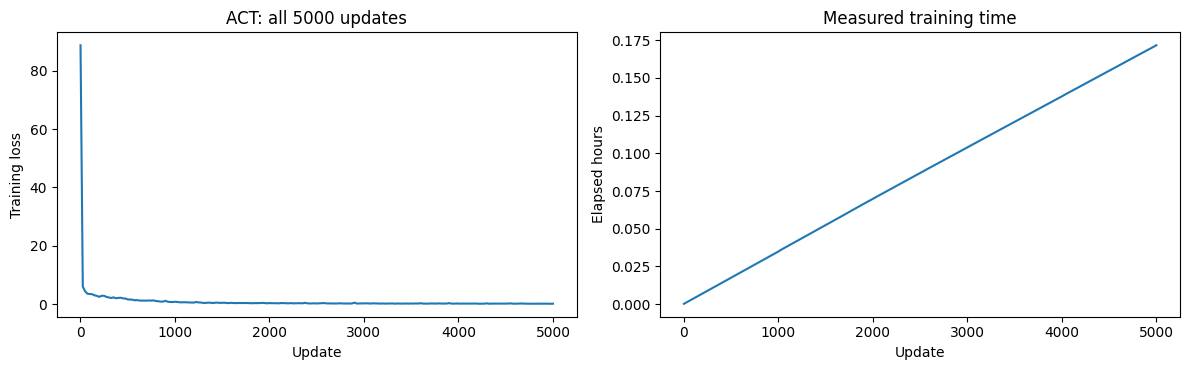

|种子|物理成功|控制步数|
|---|---|---|
|2000|False|1200|
|2001|False|1200|
|2002|True|710|
|2003|False|1200|
|2004|False|1200|
|2005|False|1200|
|2006|False|1200|
|2007|False|1200|
|2008|False|1200|
|2009|False|1200|
|2010|True|1030|
|2011|False|1200|
|2012|False|1200|
|2013|False|1200|
|2014|False|1200|
|2015|False|1200|
|2016|False|1200|
|2017|False|1200|
|2018|False|1200|
|2019|False|1200|
|2020|False|1200|
|2021|False|1200|
|2022|False|1200|
|2023|False|1200|
|2024|False|1200|
|2025|False|1200|
|2026|False|1200|
|2027|False|1200|
|2028|False|1200|
|2029|False|1200|

```json
{
  "episodes": 30,
  "physical_successes": 2,
  "seeds": [
    2000,
    2001,
    2002,
    2003,
    2004,
    2005,
    2006,
    2007,
    2008,
    2009,
    2010,
    2011,
    2012,
    2013,
    2014,
    2015,
    2016,
    2017,
    2018,
    2019,
    2020,
    2021,
    2022,
    2023,
    2024,
    2025,
    2026,
    2027,
    2028,
    2029
  ],
  "horizon": 1200,
  "weights_sha256": "e332621cc67f5462990f21316847ec082d45fc911ef70264e6d0ed54124e39fc"
}

```

In [6]:
import matplotlib.pyplot as plt
EVIDENCE = RUN if RUN_FULL else SNAPSHOT
metrics_file = EVIDENCE / "training-metrics.json"
if metrics_file.exists():
    metrics = json.loads(metrics_file.read_text())
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    axes[0].plot([r["step"] for r in metrics], [r["loss"] for r in metrics])
    axes[0].set(xlabel="Update", ylabel="Training loss", title="ACT: all 5000 updates")
    axes[1].plot([r["step"] for r in metrics], [r["elapsed_s"] / 3600 for r in metrics])
    axes[1].set(xlabel="Update", ylabel="Elapsed hours", title="Measured training time")
    fig.tight_layout(); display(fig); plt.close(fig)
    rows = [json.loads(s) for s in (EVIDENCE / "evaluation.jsonl").read_text().splitlines() if s.strip()]
    display(Markdown("|种子|物理成功|控制步数|\n|---|---|---|\n" + "\n".join(f"|{r['seed']}|{r['physical_success']}|{r.get('action_steps', '')}|" for r in rows)))
    display(Markdown("```json\n" + (EVIDENCE / "evaluation-summary.json").read_text() + "\n```"))
else:
    print("本次完整实验正在运行，最终曲线与30回合结果将在评估结束后保存。")


## 6. 本次成功与失败录像

预览和完整视频均来自本次正式评估；采集视频单独标注，不计入策略成功率。

In [7]:
media_file = SNAPSHOT / "media.json"
if media_file.exists():
    for item in json.loads(media_file.read_text()):
        display(Markdown(item["label"]))
        display(Image(filename=str(SNAPSHOT / item["preview"])))
        relative = os.path.relpath(SNAPSHOT / item["video"], Path.cwd())
        display(HTML(f'<video controls preload="metadata" width="640" src="{relative}"></video>'))
else:
    print("等待本次正式评估录像；旧结果请查看抓杯子任务入口。")


等待本次正式评估录像；旧结果请查看抓杯子任务入口。
